# Notebook 01: exploración inicial

*Usar IA sin estar convencido: discrepancia entre uso y actitud en desarrolladores de software.* Trabajo final de especialización, Maestría en Explotación de Datos y Descubrimiento del Conocimiento, FCEyN-UBA.

Carga las ediciones 2023, 2024 y 2025 del Stack Overflow Developer Survey y muestra una primera exploración: cantidad de respuestas, filtro de desarrolladores profesionales, variable a predecir y brecha entre uso y actitud favorable por año. Las funciones de carga están en `scripts/pipeline.py`.

## 1. Preparación

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import importlib.util
spec = importlib.util.spec_from_file_location("pipeline", ROOT / "scripts" / "pipeline.py")
pipeline = importlib.util.module_from_spec(spec)
spec.loader.exec_module(pipeline)

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
sns.set_theme(style="whitegrid")

print(f"Etiquetas de la variable a predecir: {pipeline.TARGET_LABELS}")

Etiquetas de la variable a predecir: {1: 'Sin discrepancia', 0: 'Con discrepancia uso-actitud'}


## 2. Carga y normalización de las tres ediciones

`pipeline.cargar_y_normalizar()` deja las tres ediciones con el mismo formato. En 2025 la pregunta de uso tiene tres respuestas afirmativas (diaria, semanal y mensual), que se unen en «Yes». En 2023 las columnas `AIBen` y `AIAcc` están invertidas respecto de los otros años. Los nombres de los roles se unifican entre ediciones.

In [2]:
df23, df24, df25 = pipeline.cargar_y_normalizar()
print("Filas y columnas por edición:")
print(f"  2023: {df23.shape}")
print(f"  2024: {df24.shape}")
print(f"  2025: {df25.shape}")

Cargados: 2023=89,184  2024=65,437  2025=49,191
Filas y columnas por edición:
  2023: (89184, 85)
  2024: (65437, 115)
  2025: (49191, 173)


## 3. Filtro: solo desarrolladores profesionales (`MainBranch`)

In [3]:
DEV_LABEL = pipeline.DEV_LABEL
filtros = pd.DataFrame({
    "Año": [2023, 2024, 2025],
    "Total respuestas": [len(df23), len(df24), len(df25)],
    "Desarrolladores profesionales": [
        (df23["MainBranch"] == DEV_LABEL).sum(),
        (df24["MainBranch"] == DEV_LABEL).sum(),
        (df25["MainBranch"] == DEV_LABEL).sum(),
    ],
})
filtros["% retenido"] = (filtros["Desarrolladores profesionales"] / filtros["Total respuestas"] * 100).round(1)
filtros

,Año,Total respuestas,Desarrolladores profesionales,% retenido
0,2023,89184,67237,75.4
1,2024,65437,50207,76.7
2,2025,49191,37467,76.2


## 4. Variable a predecir antes de restringir a usuarios

`pipeline.construir_target` define la variable a predecir:

- valor 1 (sin discrepancia): usa IA (`AISelect = Yes`) y declara una actitud favorable o muy favorable (`AISent`);
- valor 0: cualquier otro caso.

In [4]:
for df_y, year in [(df23, 2023), (df24, 2024), (df25, 2025)]:
    df_y["target"] = pipeline.construir_target(df_y)

df_full = pd.concat([df23, df24, df25], ignore_index=True)
df_full = df_full[df_full["MainBranch"] == DEV_LABEL].copy()

print(f"Desarrolladores profesionales (tres ediciones): {len(df_full):,}\n")
print("Variable a predecir por año, antes de restringir a usuarios de IA:")
print(df_full.groupby("survey_year")["target"].agg(["count", "sum", "mean"]).round(3))

Desarrolladores profesionales (tres ediciones): 154,911

Variable a predecir por año, antes de restringir a usuarios de IA:
             count    sum   mean
survey_year                     
2023         67237  25144  0.374
2024         50207  22695  0.452
2025         37467  15235  0.407


## 5. Brecha entre uso y actitud favorable por año

Es la misma medida que reportan Gillespie et al. (2025) para la población general, calculada sobre los desarrolladores profesionales de la encuesta.

In [5]:
brechas = []
for year, df_y in [(2023, df23), (2024, df24), (2025, df25)]:
    sub = df_y[df_y["MainBranch"] == DEV_LABEL]
    uso = (sub["AISelect"] == "Yes").mean() * 100
    confianza = sub["AISent"].isin(pipeline.ACTITUD_POSITIVA).mean() * 100
    brechas.append({
        "año": year, "% uso": round(uso, 1), "% actitud favorable": round(confianza, 1),
        "brecha (puntos)": round(uso - confianza, 1)
    })
brechas_df = pd.DataFrame(brechas)
brechas_df

,año,% uso,% actitud favorable,brecha (puntos)
0,2023,44.2,53.1,-9.0
1,2024,59.0,51.2,7.8
2,2025,56.1,42.2,13.9


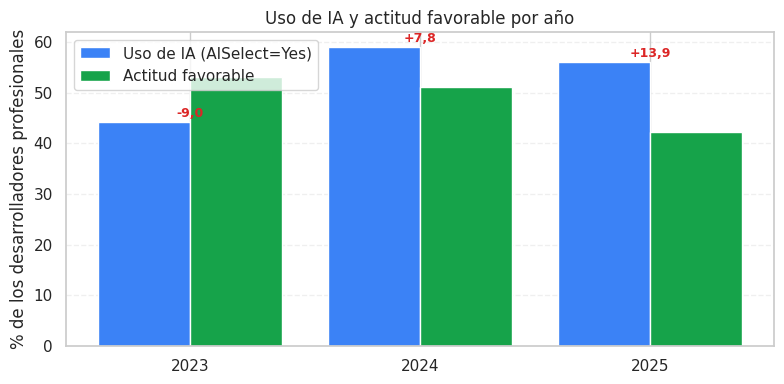

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(3)
ax.bar(x - 0.2, brechas_df["% uso"], 0.4, label="Uso de IA (AISelect=Yes)", color="#3b82f6")
ax.bar(x + 0.2, brechas_df["% actitud favorable"], 0.4, label="Actitud favorable", color="#16a34a")
ax.set_xticks(x)
ax.set_xticklabels(["2023", "2024", "2025"])
ax.set_ylabel("% de los desarrolladores profesionales")
ax.set_title("Uso de IA y actitud favorable por año")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
for i, row in brechas_df.iterrows():
    ax.text(i, row["% uso"] + 1, f"{row['brecha (puntos)']:+.1f}".replace(".", ","), ha="center", fontsize=9, color="#dc2626", fontweight="bold")
plt.tight_layout()
plt.show()

**Lectura.** La brecha cambia de signo entre 2023 y 2024. En 2023 la actitud favorable supera al uso, y en 2024 y 2025 el uso supera a la actitud favorable. En 2025 la diferencia llega a 13,9 puntos. Gillespie et al. (2025) encuentran el mismo patrón en la población general (66 % usa IA y 46 % confía en ella).

## 6. Variables del perfil profesional

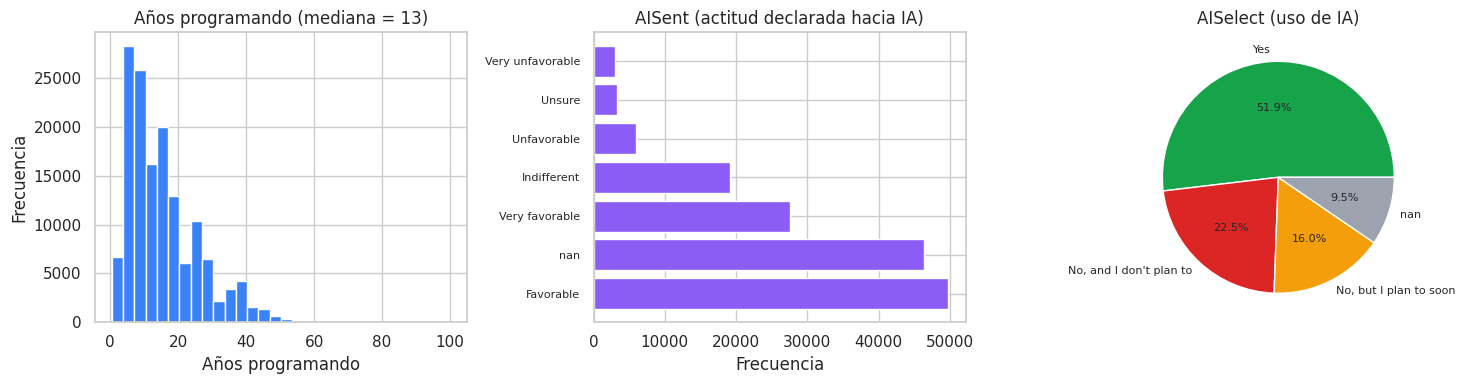

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Años programando (YearsCode): es la única medida de experiencia presente en las tres ediciones
years_code = pd.to_numeric(
    df_full["YearsCode"].replace({"Less than 1 year": 0.5, "More than 50 years": 51}), errors="coerce"
).dropna()
axes[0].hist(years_code, bins=30, color="#3b82f6", edgecolor="white")
axes[0].set_xlabel("Años programando")
axes[0].set_ylabel("Frecuencia")
axes[0].set_title(f"Años programando (mediana = {years_code.median():.0f})")

# Actitud declarada hacia la IA
sent_counts = df_full["AISent"].value_counts(dropna=False)
axes[1].barh(range(len(sent_counts)), sent_counts.values, color="#8b5cf6")
axes[1].set_yticks(range(len(sent_counts)))
axes[1].set_yticklabels([str(x)[:25] for x in sent_counts.index], fontsize=8)
axes[1].set_xlabel("Frecuencia")
axes[1].set_title("AISent (actitud declarada hacia IA)")

# Uso de IA
sel_counts = df_full["AISelect"].value_counts(dropna=False)
axes[2].pie(sel_counts.values, labels=[str(x)[:25] for x in sel_counts.index],
            autopct="%1.1f%%", colors=["#16a34a", "#dc2626", "#f59e0b", "#9ca3af"][:len(sel_counts)],
            textprops={"fontsize": 8})
axes[2].set_title("AISelect (uso de IA)")

plt.tight_layout()
plt.show()

## 7. Siguiente paso

`notebooks/02_preprocesamiento.ipynb` ejecuta el preprocesamiento completo y genera los dos archivos parquet:
- `data/df_clean.parquet`: todos los desarrolladores profesionales (154.911 filas);
- `data/df_clean_users.parquet`: solo quienes usan IA (80.369 filas).